In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
columns = [
    'Sex',
    'Length',
    'Diameter',
    'Height',
    'Whole_weight',
    'Shucked_weight',
    'Viscera_weight',
    'Shell_weight',
    'Rings'
]

df = pd.read_csv(
    'abalone.data',
    header=None,
    names=columns
)

In [3]:
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [4]:
df.shape

(4177, 9)

In [5]:
df.isnull().sum()

Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

In [6]:
duplicate_rows_df = df[df.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (0, 9)


## Descriptive Statistics Variable "Sex"

The variable "Sex" contains three distinct categories: Male (M), Female (F), and Infant (I). We examined the frequency of observations within each category and calculated their relative proportions, expressed as percentages. Additionally, a bar chart was used to visually represent the distribution of observations across the three categories.


In [7]:
df["Sex"].unique() 

<StringArray>
['M', 'F', 'I']
Length: 3, dtype: str

In [8]:
df['Sex'].value_counts()

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

In [9]:
df['Sex'].value_counts(normalize=True) * 100

Sex
M    36.581278
I    32.128322
F    31.290400
Name: proportion, dtype: float64

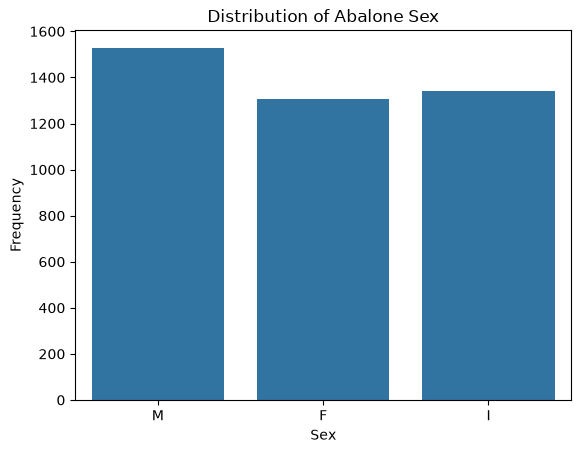

In [10]:
sns.countplot(data=df, x='Sex')

plt.title('Distribution of Abalone Sex')
plt.xlabel('Sex')
plt.ylabel('Frequency')
plt.show()

## Descriptive statistics for the "Length" category

For the “Length” variable, the data were initially examined for missing or potentially erroneous values. No missing values ​​were identified. Subsequently, a histogram was constructed to visualize the length distribution of the abalone. Additionally, a boxplot was used to examine the median, quartiles, interquartile range (IQR), minimum and maximum values, and possible outliers.

49 potential outliers were identified, representing approximately 1.17% of the total observations. The majority of these observations (41) corresponded to the “infant” category (*Infant*).

Finally, a histogram with distributions differentiated by sex was generated to compare the length of the abalone between the three categories. The results showed that abalones in the "child" category have a shorter average length of approximately 0.4, while abalone in the "male" and "female" categories show distributions with higher and relatively similar values, with a considerable overlap of around 0.6.

In [11]:
df['Length'].unique() 

array([0.455, 0.35 , 0.53 , 0.44 , 0.33 , 0.425, 0.545, 0.475, 0.55 ,
       0.525, 0.43 , 0.49 , 0.535, 0.47 , 0.5  , 0.355, 0.365, 0.45 ,
       0.38 , 0.565, 0.615, 0.56 , 0.58 , 0.59 , 0.605, 0.575, 0.68 ,
       0.665, 0.705, 0.465, 0.54 , 0.24 , 0.205, 0.21 , 0.39 , 0.46 ,
       0.325, 0.52 , 0.4  , 0.485, 0.405, 0.445, 0.245, 0.505, 0.595,
       0.31 , 0.555, 0.57 , 0.6  , 0.62 , 0.625, 0.695, 0.36 , 0.51 ,
       0.435, 0.495, 0.385, 0.515, 0.37 , 0.27 , 0.375, 0.7  , 0.71 ,
       0.265, 0.305, 0.345, 0.65 , 0.28 , 0.175, 0.17 , 0.635, 0.645,
       0.61 , 0.725, 0.235, 0.315, 0.225, 0.64 , 0.63 , 0.585, 0.42 ,
       0.335, 0.415, 0.275, 0.295, 0.075, 0.13 , 0.11 , 0.16 , 0.23 ,
       0.3  , 0.32 , 0.655, 0.66 , 0.2  , 0.165, 0.19 , 0.74 , 0.34 ,
       0.675, 0.745, 0.685, 0.69 , 0.67 , 0.29 , 0.26 , 0.395, 0.41 ,
       0.22 , 0.255, 0.735, 0.155, 0.48 , 0.195, 0.25 , 0.18 , 0.15 ,
       0.215, 0.73 , 0.715, 0.765, 0.185, 0.285, 0.72 , 0.75 , 0.755,
       0.78 , 0.815,

In [12]:
df['Length'].agg(['min', 'max'])

min    0.075
max    0.815
Name: Length, dtype: float64

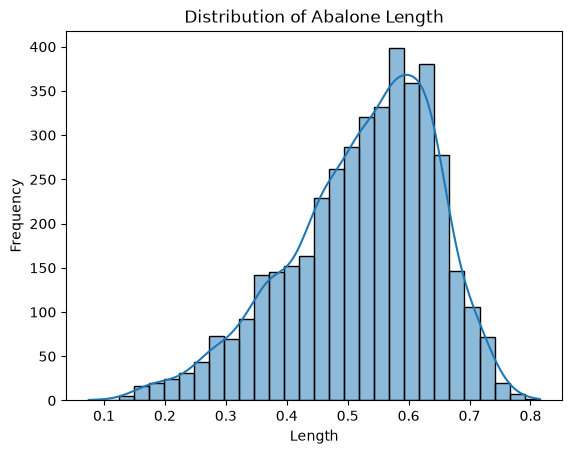

In [13]:
sns.histplot(data=df, x='Length', bins=30, kde=True)

plt.title('Distribution of Abalone Length')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

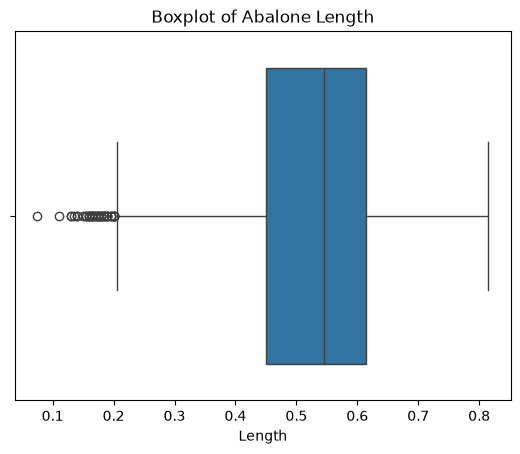

In [14]:
sns.boxplot(data=df, x='Length')

plt.title('Boxplot of Abalone Length')
plt.xlabel('Length')
plt.show()

In [15]:
Q1_length = df['Length'].quantile(0.25)
Q3_length = df['Length'].quantile(0.75)

IQR_length = Q3_length - Q1_length

print('Q1 Length:', Q1_length)
print('Q3 Length:', Q3_length)
print('IQR Length:', IQR_length)

Q1 Length: 0.45
Q3 Length: 0.615
IQR Length: 0.16499999999999998


In [16]:
lower_limit_length = Q1_length - (1.5 * IQR_length)
upper_limit_length = Q3_length + (1.5 * IQR_length)

print('Lower limit Length:', lower_limit_length)
print('Upper limit Length:', upper_limit_length)

Lower limit Length: 0.20250000000000004
Upper limit Length: 0.8624999999999999


In [17]:
outliers_length = df[
    (df['Length'] < lower_limit_length) |
    (df['Length'] > upper_limit_length)
]

print('Number of Length outliers:', len(outliers_length))

Number of Length outliers: 49


In [18]:
outlier_percentage_length = (len(outliers_length) / len(df)) * 100

print('Length outlier percentage:', round(outlier_percentage_length, 2), '%')

Length outlier percentage: 1.17 %


In [19]:
outliers_length['Sex'].value_counts()

Sex
I    41
M     8
Name: count, dtype: int64

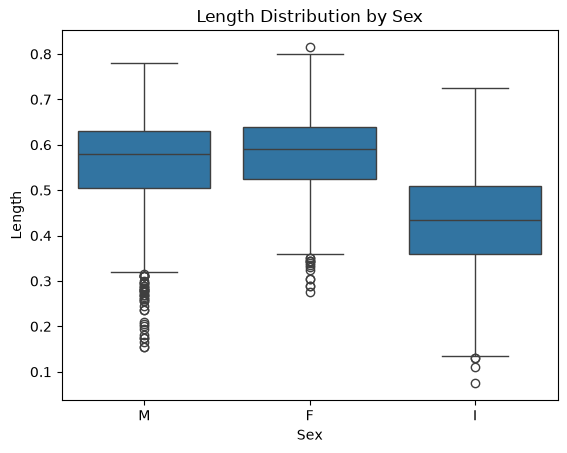

In [20]:
sns.boxplot(data=df, x='Sex', y='Length')

plt.title('Length Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Length')
plt.show()

In [21]:
df.groupby('Sex')['Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1307.0,0.579093,0.086160,0.275,0.525,0.590,0.64,0.815
I,1342.0,0.427746,0.108858,0.075,0.360,0.435,0.51,0.725
M,1528.0,0.561391,0.102697,0.155,0.505,0.580,0.63,0.780


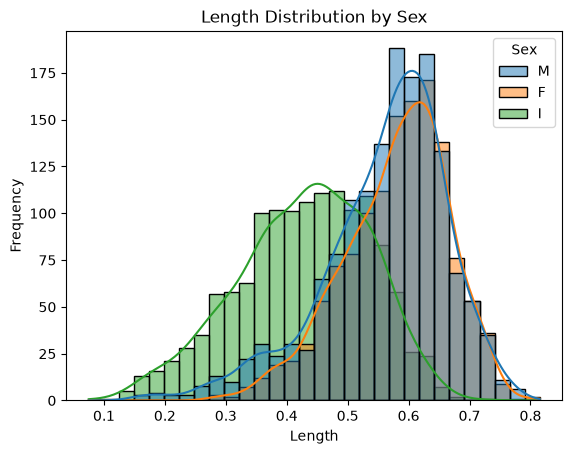

In [22]:
sns.histplot(
    data=df,
    x='Length',
    hue='Sex',
    kde=True,
    bins=30
)

plt.title('Length Distribution by Sex')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

## Descriptive statistics for the "Diameter" category

A similar analysis was conducted for the "Diameter" variable; no missing values ​​were identified, and the distribution showed patterns comparable to those observed for the "Length" variable.

Using the interquartile range (IQR) method, 59 potential outliers were identified, representing approximately 1.41% of the total observations. The majority of these (50) belonged to the "Infant" category, consistent with the findings for the previously analyzed variable.

Box plots were used to compare the diameter across the three sex categories. The results revealed patterns similar to those observed for length. Furthermore, the histograms indicated that abalones in the "Infant" category have a smaller average diameter (approximately 0.30) compared to those in the "Male" and "Female" categories, which show average values ​​of approximately 0.45.

In [23]:
df['Diameter'].unique()

array([0.365, 0.265, 0.42 , 0.255, 0.3  , 0.415, 0.425, 0.37 , 0.44 ,
       0.38 , 0.35 , 0.405, 0.355, 0.4  , 0.28 , 0.34 , 0.295, 0.32 ,
       0.275, 0.48 , 0.45 , 0.445, 0.475, 0.47 , 0.56 , 0.525, 0.55 ,
       0.29 , 0.335, 0.175, 0.15 , 0.375, 0.245, 0.41 , 0.36 , 0.31 ,
       0.385, 0.19 , 0.345, 0.325, 0.495, 0.39 , 0.235, 0.51 , 0.465,
       0.535, 0.435, 0.43 , 0.395, 0.305, 0.195, 0.54 , 0.26 , 0.2  ,
       0.33 , 0.23 , 0.285, 0.52 , 0.455, 0.205, 0.13 , 0.5  , 0.515,
       0.485, 0.46 , 0.545, 0.57 , 0.575, 0.16 , 0.21 , 0.49 , 0.25 ,
       0.27 , 0.505, 0.215, 0.225, 0.055, 0.1  , 0.09 , 0.12 , 0.53 ,
       0.145, 0.22 , 0.6  , 0.58 , 0.585, 0.565, 0.555, 0.185, 0.165,
       0.125, 0.59 , 0.14 , 0.11 , 0.155, 0.315, 0.24 , 0.17 , 0.18 ,
       0.105, 0.595, 0.135, 0.625, 0.63 , 0.61 , 0.65 , 0.62 , 0.605,
       0.095, 0.115, 0.615])

In [24]:
df['Diameter'].agg(['min', 'max'])

min    0.055
max    0.650
Name: Diameter, dtype: float64

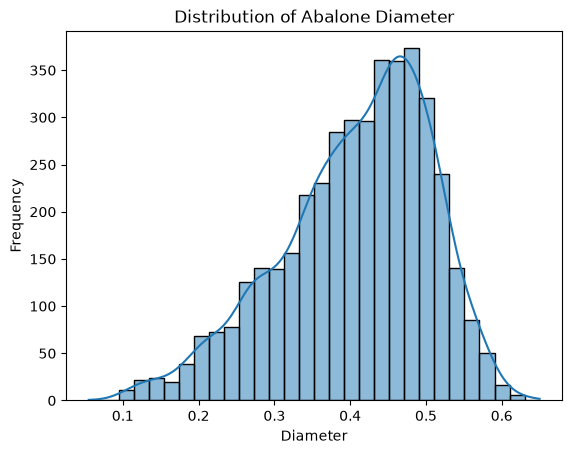

In [25]:
sns.histplot(data=df, x='Diameter', bins=30, kde=True)

plt.title('Distribution of Abalone Diameter')
plt.xlabel('Diameter')
plt.ylabel('Frequency')
plt.show()

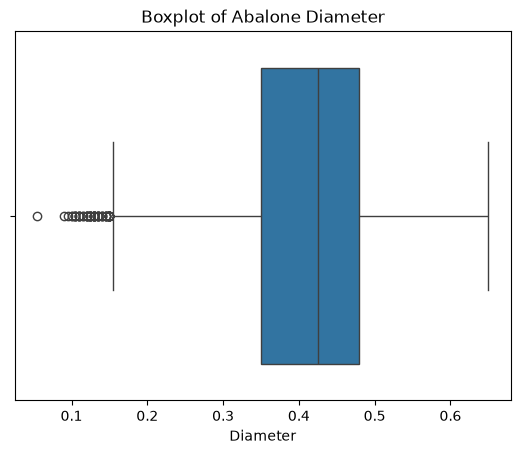

In [26]:
sns.boxplot(data=df, x='Diameter')

plt.title('Boxplot of Abalone Diameter')
plt.xlabel('Diameter')
plt.show()

In [27]:
Q1_diameter = df['Diameter'].quantile(0.25)
Q3_diameter = df['Diameter'].quantile(0.75)

IQR_diameter = Q3_diameter - Q1_diameter

print('Q1 Diameter:', Q1_diameter)
print('Q3 Diameter:', Q3_diameter)
print('IQR Diameter:', IQR_diameter)

Q1 Diameter: 0.35
Q3 Diameter: 0.48
IQR Diameter: 0.13


In [28]:
lower_limit_diameter = Q1_diameter - (1.5 * IQR_diameter)
upper_limit_diameter = Q3_diameter + (1.5 * IQR_diameter)

print('Lower limit Diameter:', lower_limit_diameter)
print('Upper limit Diameter:', upper_limit_diameter)

Lower limit Diameter: 0.15499999999999997
Upper limit Diameter: 0.675


In [29]:
outliers_diameter = df[
    (df['Diameter'] < lower_limit_diameter) |
    (df['Diameter'] > upper_limit_diameter)
]

print('Number of Diameter outliers:', len(outliers_diameter))

Number of Diameter outliers: 59


In [30]:
outlier_percentage_diameter = (len(outliers_diameter) / len(df)) * 100

print('Diameter outlier percentage:', round(outlier_percentage_diameter, 2), '%')

Diameter outlier percentage: 1.41 %


In [31]:
outliers_diameter['Sex'].value_counts()

Sex
I    50
M     9
Name: count, dtype: int64

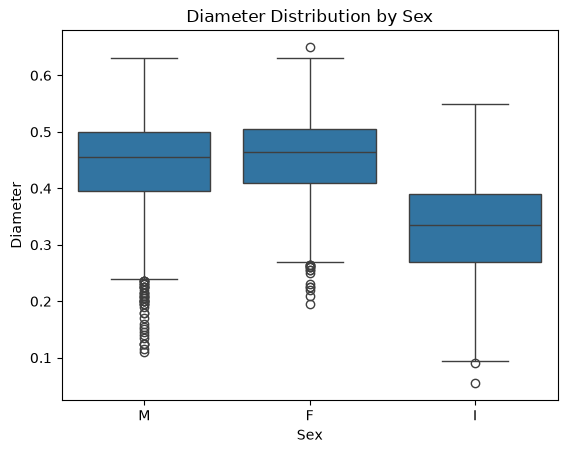

In [32]:
sns.boxplot(data=df, x='Sex', y='Diameter')

plt.title('Diameter Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Diameter')
plt.show()

In [33]:
df.groupby('Sex')['Diameter'].describe()

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1307.0,0.454732,0.070954,0.195,0.410,0.465,0.505,0.65
I,1342.0,0.326494,0.088109,0.055,0.270,0.335,0.390,0.55
M,1528.0,0.439287,0.084398,0.110,0.395,0.455,0.500,0.63


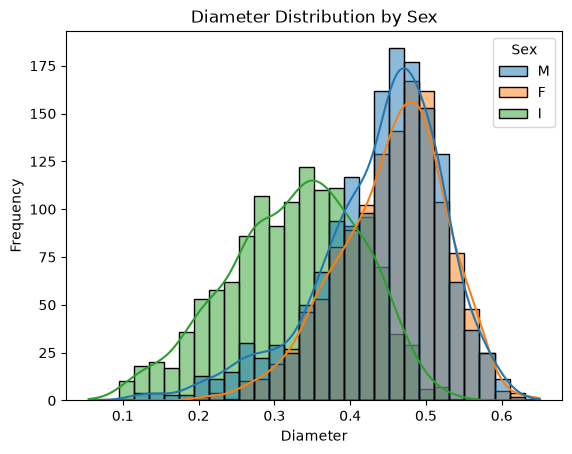

In [34]:
sns.histplot(
    data=df,
    x='Diameter',
    hue='Sex',
    kde=True,
    bins=30
)

plt.title('Diameter Distribution by Sex')
plt.xlabel('Diameter')
plt.ylabel('Frequency')
plt.show()

## Descriptive statistics for the "Height" category

The "Height" variable showed similar distributions for male and female abalones, with the majority of observations concentrated between 0.14 and 0.18. In contrast, the "Infant" category exhibited lower values, with a peak around 0.10 and a notably lower median.

Regarding outliers, most of those at the lower end belonged to the "Juvenile" category, suggesting that these values ​​might be naturally associated with their smaller size rather than resulting from measurement errors. However, two exceptionally high observations (1417 and 2051) with height values ​​of 0.515 and 1.130, respectively—were identified as potentially anomalous when compared against length and diameter. As these accounted for only 0.05% of the original dataset, they were removed, while the remaining outliers were retained.

In [35]:
df['Height'].unique()

array([0.095, 0.09 , 0.135, 0.125, 0.08 , 0.15 , 0.14 , 0.11 , 0.145,
       0.1  , 0.13 , 0.085, 0.155, 0.165, 0.185, 0.18 , 0.175, 0.2  ,
       0.105, 0.045, 0.055, 0.05 , 0.12 , 0.07 , 0.16 , 0.06 , 0.17 ,
       0.195, 0.19 , 0.115, 0.075, 0.065, 0.215, 0.21 , 0.23 , 0.205,
       0.22 , 0.04 , 0.01 , 0.03 , 0.035, 0.225, 0.24 , 0.235, 0.02 ,
       0.025, 0.015, 0.   , 0.515, 0.25 , 1.13 ])

encontramos un error de peso 0.0 veamos que hacer 

In [36]:
df[df['Height'] == 0]

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


In [37]:
df = df[df['Height'] != 0]

In [38]:
(df['Height'] == 0).sum()

np.int64(0)

In [39]:
df['Height'].agg(['min', 'max'])

min    0.01
max    1.13
Name: Height, dtype: float64

In [40]:
Q1_height = df['Height'].quantile(0.25)
Q3_height = df['Height'].quantile(0.75)

IQR_height = Q3_height - Q1_height

print('Q1 Height:', Q1_height)
print('Q3 Height:', Q3_height)
print('IQR Height:', IQR_height)

Q1 Height: 0.115
Q3 Height: 0.165
IQR Height: 0.05


In [41]:
lower_limit_height = Q1_height - (1.5 * IQR_height)
upper_limit_height = Q3_height + (1.5 * IQR_height)

print('Lower limit Height:', lower_limit_height)
print('Upper limit Height:', upper_limit_height)

Lower limit Height: 0.039999999999999994
Upper limit Height: 0.24000000000000002


In [42]:
outliers_height = df[
    (df['Height'] < lower_limit_height) |
    (df['Height'] > upper_limit_height)
]

print('Number of Height outliers:', len(outliers_height))

Number of Height outliers: 27


In [43]:
outlier_percentage_height = (len(outliers_height) / len(df)) * 100

print('Height outlier percentage:', round(outlier_percentage_height, 2), '%')

Height outlier percentage: 0.65 %


In [44]:
outliers_height['Sex'].value_counts()

Sex
I    20
F     4
M     3
Name: count, dtype: int64

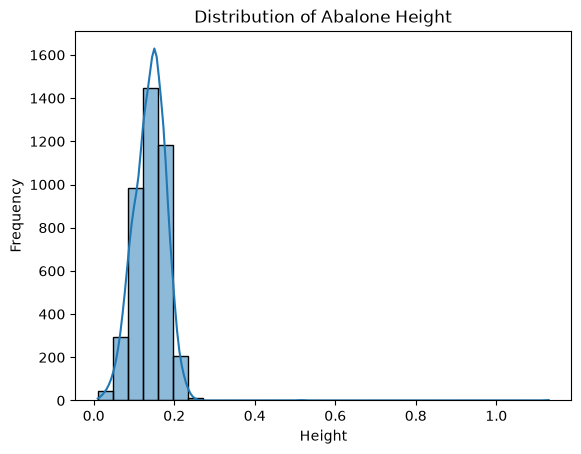

In [45]:
sns.histplot(data=df, x='Height', bins=30, kde=True)

plt.title('Distribution of Abalone Height')
plt.xlabel('Height')
plt.ylabel('Frequency')
plt.show()

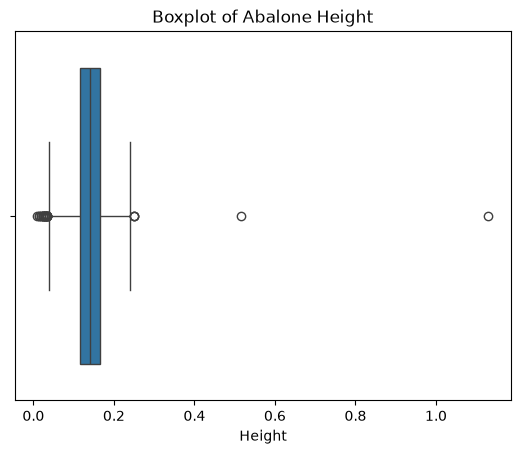

In [46]:
sns.boxplot(data=df, x='Height')

plt.title('Boxplot of Abalone Height')
plt.xlabel('Height')
plt.show()

In [47]:
df.loc[df['Height'] < lower_limit_height, 'Sex'].value_counts()

Sex
I    20
F     1
M     1
Name: count, dtype: int64

Outliers were identified in the "Height" variable. Specifically, observations falling below the lower limit were analysed, and their distribution across the different "Sex" categories was examined. The majority of these observations belonged to the "Infant" category. This suggests that the lower Height values may be associated with the naturally smaller size of younger abalones rather than indicating measurement errors. Consequently, these observations were retained in the dataset.

In [48]:
df.loc[df['Height'] > upper_limit_height, 'Sex'].value_counts()

Sex
F    3
M    2
Name: count, dtype: int64

In [49]:
df.loc[df['Height'] > upper_limit_height]

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
1417,M,0.705,0.565,0.515,2.2100,1.1075,0.4865,0.5120,10
1428,F,0.815,0.650,0.250,2.2550,0.8905,0.4200,0.7975,14
1763,M,0.775,0.630,0.250,2.7795,1.3485,0.7600,0.5780,12
2051,F,0.455,0.355,1.130,0.5940,0.3320,0.1160,0.1335,8
2179,F,0.595,0.470,0.250,1.2830,0.4620,0.2475,0.4450,14


In [50]:
percentage_removed = (2 / len(df)) * 100

print('Percentage of observations:', round(percentage_removed, 2), '%')

Percentage of observations: 0.05 %


In [51]:
df = df.drop(index=[1417, 2051])

After analysing the upper outliers in the "Height" variable, two observations (1417 and 2051) were identified as exceptionally high compared with the overall distribution, with values of 0.515 and 1.130, respectively. When examined alongside other variables, particularly Length and Diameter, these measurements appeared unusually disproportionate. These two observations accounted for only 0.05% of the dataset. Therefore, they were removed to minimise the influence of potentially anomalous measurements and maintain a dataset representative of the vast majority of the abalone population.

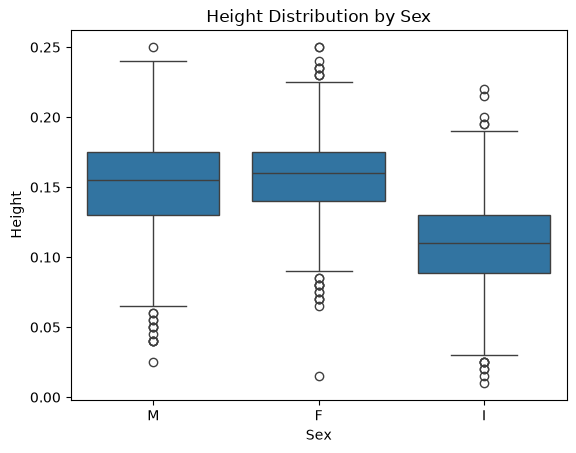

In [52]:
sns.boxplot(data=df, x='Sex', y='Height')

plt.title('Height Distribution by Sex')
plt.xlabel('Sex')
plt.ylabel('Height')
plt.show()

In [53]:
df.shape

(4173, 9)

In [54]:
df.groupby('Sex')['Height'].describe()

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1306.0,0.157266,0.029588,0.015,0.14000,0.160,0.175,0.25
I,1340.0,0.108157,0.031745,0.010,0.08875,0.110,0.130,0.22
M,1527.0,0.151143,0.033548,0.025,0.13000,0.155,0.175,0.25


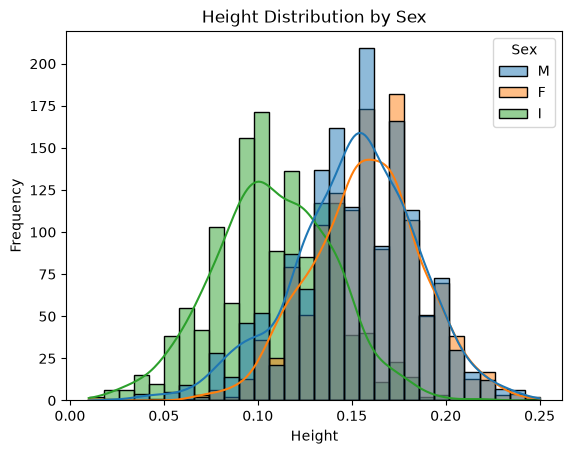

In [55]:
sns.histplot(
    data=df,
    x='Height',
    hue='Sex',
    kde=True,
    bins=30
)

plt.title('Height Distribution by Sex')
plt.xlabel('Height')
plt.ylabel('Frequency')
plt.show()

## Descriptive statistics for the "Whole_weight", "Shucked_weight", "Viscera_weight" and "Shell_weight" categories

In [56]:
components = [
    'Shucked_weight',
    'Viscera_weight',
    'Shell_weight'
]

for column in components:
    count = (df[column] > df['Whole_weight']).sum()

    print(f"{column} > Whole_weight: {count}")

Shucked_weight > Whole_weight: 4
Viscera_weight > Whole_weight: 0
Shell_weight > Whole_weight: 0


We have 4 inconsistent observations; since these represent a portion of the abalone's weight, they cannot exceed the total weight.

In [57]:
invalid_rows = df[
    df['Shucked_weight'] > df['Whole_weight']
]

invalid_rows[
    ['Whole_weight', 'Shucked_weight',
     'Viscera_weight', 'Shell_weight']
]

,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight
1216,0.1055,0.4350,0.0150,0.0400
2627,0.1055,0.4950,0.0190,0.0315
2641,0.1315,0.2025,0.0875,0.1230
3086,0.2040,0.3045,0.0460,0.0595


In [58]:
df = df[df['Shucked_weight'] <= df['Whole_weight']].copy()

In [59]:
print("Updated dataset shape:", df.shape)

Updated dataset shape: (4169, 9)


Logically, the sum of our three variables (Shucked_weight, Viscera_weight, and Shell_weight) should not exceed Whole_weight, so we will verify this.

In [60]:
df['Total_components'] = (
    df['Shucked_weight'] +
    df['Viscera_weight'] +
    df['Shell_weight']
)

Exceeding = (
    df['Total_components'] > df['Whole_weight']
).sum()

print("Observations exceeding Whole_weight:", Exceeding)

Observations exceeding Whole_weight: 150


We have 150 cases where the sum of the components exceeds the total weight; we are going to investigate these observations.

In [61]:
df['Weight_excess'] = (
    df['Total_components'] - df['Whole_weight']
)

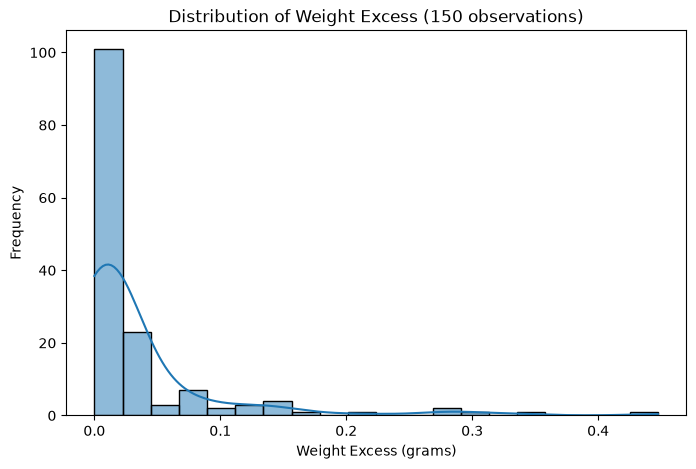

In [62]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df[df['Total_components'] > df['Whole_weight']],
    x='Weight_excess',
    bins=20,
    kde=True
)

plt.title('Distribution of Weight Excess (150 observations)')
plt.xlabel('Weight Excess (grams)')
plt.ylabel('Frequency')

plt.show()

The histogram revealed that 150 observations showed a positive weight excess that is, the sum of the weight of the flesh (excluding the shell), the viscera, and the shell exceeded the total recorded weight. Since some of these discrepancies were minor while others were substantial, it proved useful to establish a criterion to distinguish between small and large weight excesses.

In [63]:
Within_range = df.loc[
    df['Total_components'] <= df['Whole_weight'],
    'Weight_excess'
]

Q1_valid = Within_range.quantile(0.25)
Q3_valid = Within_range.quantile(0.75)

IQR_valid = Q3_valid - Q1_valid

Lower_valid = Q1_valid - 1.5 * IQR_valid
Upper_valid = Q3_valid + 1.5 * IQR_valid

print("Q1:", Q1_valid)
print("Q3:", Q3_valid)
print("IQR:", IQR_valid)
print("Lower limit:", Lower_valid)
print("Upper limit:", Upper_valid)

Q1: -0.0694999999999999
Q3: -0.019500000000000045
IQR: 0.04999999999999985
Lower limit: -0.14449999999999968
Upper limit: 0.05549999999999973


To establish a reference threshold, we selected observations in which the sum of the three components did not exceed the total weight (*Whole_weight*). We calculated the first quartile (Q1 = -0.0695 g), the third quartile (Q3 = -0.0195 g), and the interquartile range (IQR = 0.05 g), obtaining an upper limit of 0.0555 g.

This threshold was then applied to the 150 observations with positive weight excesses. A total of 124 observations (82.67%) fell within the reference limit, while 26 (17.33%) exceeded it. This classification helped distinguish relatively small excesses from larger discrepancies for further investigation.

In [66]:
Positive_excess = df[df['Weight_excess'] > 0]

Small_excess = Positive_excess[Positive_excess['Weight_excess'] <= Upper_valid]
High_excess = Positive_excess[Positive_excess['Weight_excess'] > Upper_valid]

print("Small excess:", len(Small_excess))
print("High excess:", len(High_excess))

print("Small excess (%):", round(len(Small_excess) / len(Positive_excess) * 100, 2))
print("High excess (%):", round(len(High_excess) / len(Positive_excess) * 100, 2))

Small excess: 124
High excess: 26
Small excess (%): 82.67
High excess (%): 17.33


In [68]:
df = df.drop(High_excess.index).copy()

The 26 observations that exceeded the upper reference limit (0.0555 g) were removed from the dataset because they showed unusually large differences between the sum of the three weight components and the total weight (Whole_weight). These values exceeded the threshold established using the interquartile range (IQR) method. Their removal was considered an exploratory data-cleaning step to reduce the influence of unusually large differences on subsequent analyses.

For the remaining observations, values exceeding the reference threshold will be capped at 0.0555 g. This approach allows us to retain these observations while limiting the influence of unusually high excess values.

In [69]:
df.loc[df['Weight_excess'] > Upper_valid, 'Weight_excess'] = Upper_valid

In [70]:
print("Maximum Weight_excess:", df['Weight_excess'].max())
print("Dataset shape:", df.shape)

Maximum Weight_excess: 0.04349999999999987
Dataset shape: (4143, 11)


In [71]:
original_weights = [
    'Whole_weight',
    'Shucked_weight',
    'Viscera_weight',
    'Shell_weight'
]

for column in original_weights:
    print(column, ":", (df[column] < 0).sum())

Whole_weight : 0
Shucked_weight : 0
Viscera_weight : 0
Shell_weight : 0


## Descriptive statistics for the "Rings" category